In [10]:
import os
import time
import cv2
import numpy as np
import torch
import glob
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

print("1. Membaca Struktur Asli Berdasarkan Screenshot...")
start_time = time.time()

# Cari otomatis letak dataset Artifact di Kaggle kamu
base_dir_list = glob.glob('/kaggle/input/datasets/awsaf49/artifact-dataset')
if not base_dir_list:
    raise RuntimeError("Dataset tidak ditemukan. Pastikan panel kanan udah nyala.")
base_dir = base_dir_list[0]

# KUNCI JAWABAN: Keyword berdasarkan nama folder di screenshot kamu
real_keywords = ['afhq', 'celebahq', 'coco', 'ffhq', 'imagenet']
fake_keywords = ['gan', 'cips', 'ddpm', 'diffusion', 'synthetic', 'glide', 'lama']

real_files = []
fake_files = []
limit = 30000

print("Menyedot 30k gambar Real dan Fake secara spesifik...")
for root, dirs, files in os.walk(base_dir):
    # Kalau kuota udah penuh, LANGSUNG STOP biar gak buang waktu!
    if len(real_files) >= limit and len(fake_files) >= limit:
        break
        
    path_lower = root.lower()
    
    # Cek apakah folder saat ini masuk kategori Real atau Fake
    is_real = any(k in path_lower for k in real_keywords)
    is_fake = any(k in path_lower for k in fake_keywords)
    
    if is_real and len(real_files) < limit:
        for f in files:
            if f.lower().endswith(('.jpg', '.png', '.jpeg', '.webp')):
                real_files.append(os.path.join(root, f))
                if len(real_files) >= limit: break
                
    elif is_fake and len(fake_files) < limit:
        for f in files:
            if f.lower().endswith(('.jpg', '.png', '.jpeg', '.webp')):
                fake_files.append(os.path.join(root, f))
                if len(fake_files) >= limit: break

print(f"Selesai! Waktu sedot: {time.time() - start_time:.2f} detik")
print(f"Total Dapet -> Real: {len(real_files)} | Fake: {len(fake_files)}")

if len(real_files) == 0 or len(fake_files) == 0:
    raise RuntimeError("Gagal memuat. Pastikan struktur dataset belum berubah.")

print("\n2. Memecah proporsi 80:10:10...")
all_files = real_files + fake_files
all_labels = [1]*len(real_files) + [0]*len(fake_files) 

train_files, temp_files, train_labels, temp_labels = train_test_split(
    all_files, all_labels, test_size=0.2, random_state=42, stratify=all_labels
)

val_files, test_files, val_labels, test_labels = train_test_split(
    temp_files, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels
)

# 3. KELAS DATASET ANTI-BADAI (Menghindari gambar corrupt)
class BulletproofDataset(Dataset):
    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = file_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img_path = self.file_paths[idx]
        label = self.labels[idx]
        
        # Pakai cv2 biar kalau ada gambar rusak nggak bikin error
        img = cv2.imread(img_path)
        if img is None:
            img = np.zeros((224, 224, 3), dtype=np.uint8)
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
        if self.transform:
            img = self.transform(img)
            
        return img, label

print("\n3. Menyuntikkan ke DataLoader PyTorch...")

train_transform = transforms.Compose([
    transforms.ToPILImage(), 
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_ds = BulletproofDataset(train_files, train_labels, transform=train_transform)
val_ds = BulletproofDataset(val_files, val_labels, transform=test_transform)
test_ds = BulletproofDataset(test_files, test_labels, transform=test_transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)

print("--- DATALOADER AMAN SENTOSA! SILAKAN LANGSUNG RUN TRAINING LOOPNYA! ---")

1. Membaca Struktur Asli Berdasarkan Screenshot...
Menyedot 30k gambar Real dan Fake secara spesifik...
Selesai! Waktu sedot: 119.72 detik
Total Dapet -> Real: 30000 | Fake: 30000

2. Memecah proporsi 80:10:10...

3. Menyuntikkan ke DataLoader PyTorch...
--- DATALOADER AMAN SENTOSA! SILAKAN LANGSUNG RUN TRAINING LOOPNYA! ---


In [11]:
import torch.nn as nn
import torchvision.models as models
from sklearn.metrics import classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device yang dipakai: {device}")

print("\nMembangun arsitektur ResNet-50 & EfficientNet-B0...")
resnet_model = models.resnet50(weights='IMAGENET1K_V1')
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 2)
resnet_model = resnet_model.to(device)

eff_model = models.efficientnet_b0(weights='IMAGENET1K_V1')
eff_model.classifier[1] = nn.Linear(eff_model.classifier[1].in_features, 2)
eff_model = eff_model.to(device)

criterion = nn.CrossEntropyLoss()
opt_resnet = torch.optim.Adam(resnet_model.parameters(), lr=0.001)
opt_eff = torch.optim.Adam(eff_model.parameters(), lr=0.001)


Device yang dipakai: cuda

Membangun arsitektur ResNet-50 & EfficientNet-B0...
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 219MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 136MB/s] 


In [12]:
import time

def train_model(model, optimizer, model_name, num_epochs=5):
    print(f"\n========== MEMULAI TRAINING: {model_name} ==========")
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(num_epochs):
        start_time = time.time()

        model.train()
        running_loss, correct_preds, total_preds = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct_preds += torch.sum(preds == labels.data)
            total_preds += labels.size(0)
            
        epoch_train_loss = running_loss / total_preds
        epoch_train_acc = correct_preds.double() / total_preds

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += torch.sum(preds == labels.data)
                val_total += labels.size(0)
                
        epoch_val_loss = val_loss / val_total
        epoch_val_acc = val_correct.double() / val_total
        time_elapsed = time.time() - start_time
        
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc.item())
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc.item())
        
        print(f"Epoch {epoch+1}/{num_epochs} | {time_elapsed:.0f} detik | Train Acc: {epoch_train_acc:.4f} | Val Acc: {epoch_val_acc:.4f}")
        
    return model, history

resnet_model, resnet_history = train_model(resnet_model, opt_resnet, "ResNet-50", num_epochs=5)
eff_model, eff_history = train_model(eff_model, opt_eff, "EfficientNet-B0", num_epochs=5)

print("\nMenyimpan bobot model ke disk...")
torch.save(resnet_model.state_dict(), '/kaggle/working/resnet50_artifact.pth')
torch.save(eff_model.state_dict(), '/kaggle/working/efficientnetB0_artifact.pth')


========== MEMULAI TRAINING: ResNet-50 ==========
Epoch 1/5 | 561 detik | Train Acc: 0.9100 | Val Acc: 0.9298
Epoch 2/5 | 568 detik | Train Acc: 0.9335 | Val Acc: 0.9427
Epoch 3/5 | 566 detik | Train Acc: 0.9415 | Val Acc: 0.9512
Epoch 4/5 | 567 detik | Train Acc: 0.9470 | Val Acc: 0.9488
Epoch 5/5 | 566 detik | Train Acc: 0.9488 | Val Acc: 0.9398

========== MEMULAI TRAINING: EfficientNet-B0 ==========
Epoch 1/5 | 271 detik | Train Acc: 0.9507 | Val Acc: 0.9653
Epoch 2/5 | 270 detik | Train Acc: 0.9704 | Val Acc: 0.9748
Epoch 3/5 | 272 detik | Train Acc: 0.9765 | Val Acc: 0.9827
Epoch 4/5 | 274 detik | Train Acc: 0.9803 | Val Acc: 0.9885
Epoch 5/5 | 272 detik | Train Acc: 0.9842 | Val Acc: 0.9800

Menyimpan bobot model ke disk...


In [13]:
def evaluate_model(model, model_name):
    print(f"\n========== HASIL CLASSIFICATION REPORT: {model_name} ==========")
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    print(classification_report(all_labels, all_preds, target_names=['Fake (0)', 'Real (1)'], digits=4))

evaluate_model(resnet_model, "ResNet-50")
evaluate_model(eff_model, "EfficientNet-B0")


========== HASIL CLASSIFICATION REPORT: ResNet-50 ==========
              precision    recall  f1-score   support

    Fake (0)     0.9728    0.9070    0.9388      3000
    Real (1)     0.9129    0.9747    0.9428      3000

    accuracy                         0.9408      6000
   macro avg     0.9429    0.9408    0.9408      6000
weighted avg     0.9429    0.9408    0.9408      6000


========== HASIL CLASSIFICATION REPORT: EfficientNet-B0 ==========
              precision    recall  f1-score   support

    Fake (0)     0.9604    0.9943    0.9771      3000
    Real (1)     0.9941    0.9590    0.9762      3000

    accuracy                         0.9767      6000
   macro avg     0.9773    0.9767    0.9767      6000
weighted avg     0.9773    0.9767    0.9767      6000



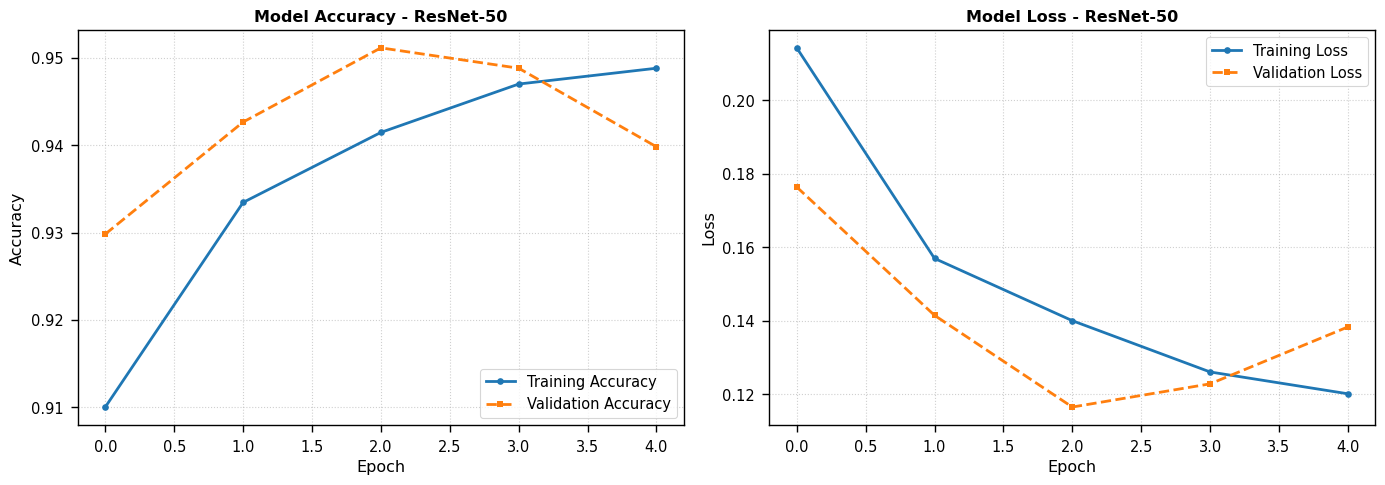

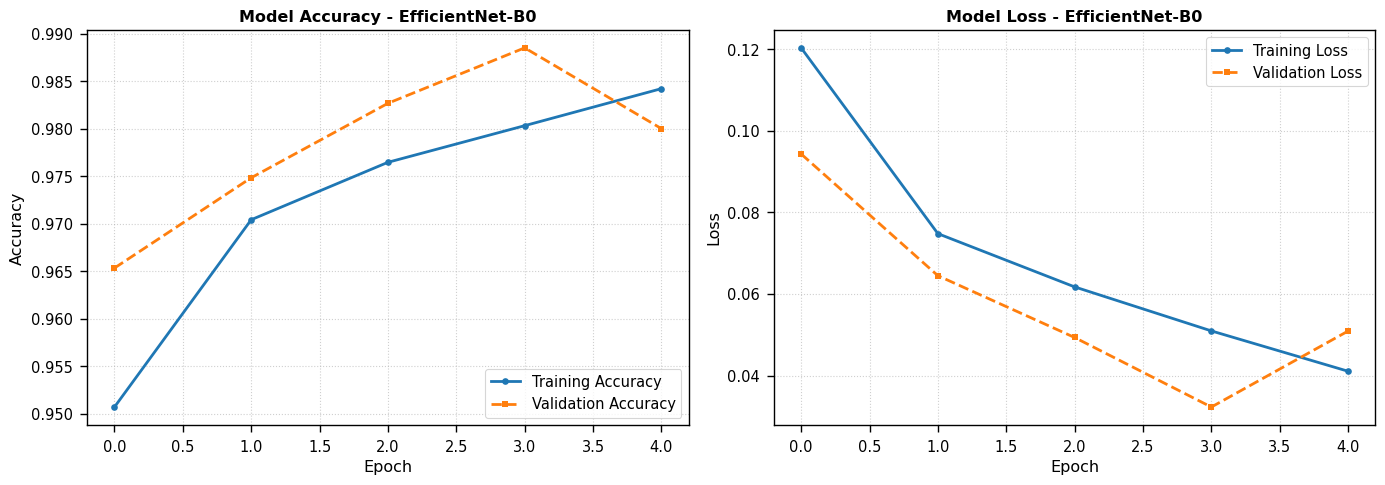

Menghitung prediksi untuk Confusion Matrix ResNet-50...

--- CLASSIFICATION REPORT: ResNet-50 ---
                  precision    recall  f1-score   support

AI-Generated (0)     0.9728    0.9070    0.9388      3000
  Real Image (1)     0.9129    0.9747    0.9428      3000

        accuracy                         0.9408      6000
       macro avg     0.9429    0.9408    0.9408      6000
    weighted avg     0.9429    0.9408    0.9408      6000



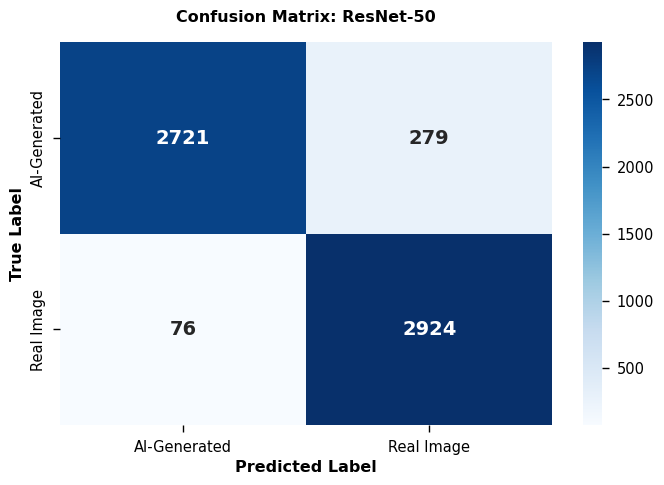

Menghitung prediksi untuk Confusion Matrix EfficientNet-B0...

--- CLASSIFICATION REPORT: EfficientNet-B0 ---
                  precision    recall  f1-score   support

AI-Generated (0)     0.9604    0.9943    0.9771      3000
  Real Image (1)     0.9941    0.9590    0.9762      3000

        accuracy                         0.9767      6000
       macro avg     0.9773    0.9767    0.9767      6000
    weighted avg     0.9773    0.9767    0.9767      6000



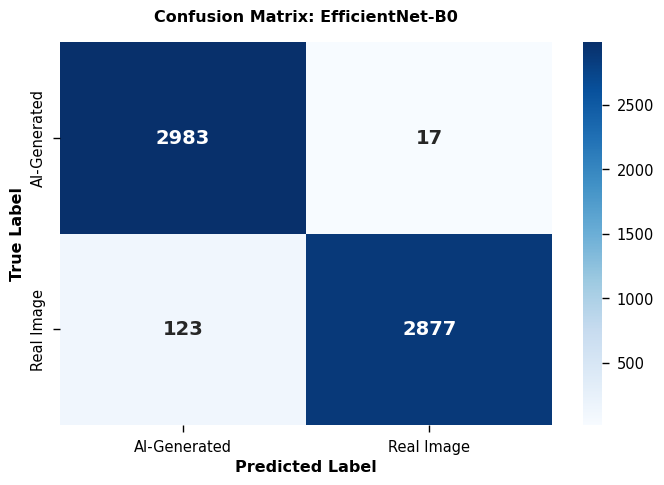

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import torch

plt.style.use('seaborn-v0_8-paper')
sns.set_context("paper", font_scale=1.2)

def plot_journal_history(history, model_name):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    
    # Grafik Akurasi
    ax[0].plot(history['train_acc'], label='Training Accuracy', color='#1f77b4', linewidth=2, marker='o')
    ax[0].plot(history['val_acc'], label='Validation Accuracy', color='#ff7f0e', linewidth=2, linestyle='--', marker='s')
    ax[0].set_title(f'Model Accuracy - {model_name}', fontweight='bold')
    ax[0].set_xlabel('Epoch')
    ax[0].set_ylabel('Accuracy')
    ax[0].legend(loc='lower right')
    ax[0].grid(True, linestyle=':', alpha=0.6)

    # Grafik Loss
    ax[1].plot(history['train_loss'], label='Training Loss', color='#1f77b4', linewidth=2, marker='o')
    ax[1].plot(history['val_loss'], label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--', marker='s')
    ax[1].set_title(f'Model Loss - {model_name}', fontweight='bold')
    ax[1].set_xlabel('Epoch')
    ax[1].set_ylabel('Loss')
    ax[1].legend(loc='upper right')
    ax[1].grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/history_{model_name}.png', dpi=300, bbox_inches='tight')
    plt.show()

def plot_journal_cm(model, model_name):
    model.eval()
    all_preds = []
    all_labels = []
    
    print(f"Menghitung prediksi untuk Confusion Matrix {model_name}...")
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    report = classification_report(all_labels, all_preds, target_names=['AI-Generated (0)', 'Real Image (1)'], digits=4)
    print(f"\n--- CLASSIFICATION REPORT: {model_name} ---\n{report}")

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True, 
                xticklabels=['AI-Generated', 'Real Image'], 
                yticklabels=['AI-Generated', 'Real Image'],
                annot_kws={"size": 14, "weight": "bold"})
    
    plt.title(f'Confusion Matrix: {model_name}', fontweight='bold', pad=15)
    plt.ylabel('True Label', fontweight='bold')
    plt.xlabel('Predicted Label', fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/cm_{model_name}.png', dpi=300, bbox_inches='tight')
    plt.show()

# Eksekusi (Nama variabel disesuaikan dengan hasil training sebelumnya)
plot_journal_history(resnet_history, "ResNet-50")
plot_journal_history(eff_history, "EfficientNet-B0")

plot_journal_cm(resnet_model, "ResNet-50")
plot_journal_cm(eff_model, "EfficientNet-B0")

In [2]:
import torch

def cek_distribusi_loader(loader, nama_fase):
    real_count = 0
    fake_count = 0
    
    # Membongkar isi keranjang DataLoader
    for images, labels in loader:
        real_count += torch.sum(labels == 1).item()
        fake_count += torch.sum(labels == 0).item()
        
    total = real_count + fake_count
    print(f"{nama_fase} ({total} citra)")
    print(f"   -> Real Image (1)  : {real_count}")
    print(f"   -> AI-Generated (0): {fake_count}\n")

print("=== CEK DISTRIBUSI KELAS LANGSUNG DARI DATALOADER ===\n")

# Pastikan train_loader, val_loader, dan test_loader sudah ter-run sebelumnya
try:
    cek_distribusi_loader(train_loader, "1. FASE TRAINING")
    cek_distribusi_loader(val_loader, "2. FASE VALIDATION")
    cek_distribusi_loader(test_loader, "3. FASE TESTING")
    print("=====================================================")
except NameError:
    print("Wah, train_loader-nya belum ada. Pastikan kamu nge-RUN cell DataLoader (persiapan data) dulu ya sebelum nge-run cell ini!")

=== CEK DISTRIBUSI KELAS LANGSUNG DARI DATALOADER ===

Wah, train_loader-nya belum ada. Pastikan kamu nge-RUN cell DataLoader (persiapan data) dulu ya sebelum nge-run cell ini!
